# Grid and metrics on the C2 blade

This notebook follows one cascade from its geometry to the geometric fields of Aungier's transformed blade-to-blade
equations [R. H. Aungier, *Axial-Flow Compressors*, ASME Press, 2003, Chapter 5]. It shows what `grid.py` and
`metrics.py` compute, why, and how each step can be checked.

> **Status (2026-11-11)**
>
> - **The solver goes with C2 only for now.** `grid.py` takes the blade-wall **locations** and `metrics.py` the
>   blade-wall **angles** from the C2 geometry: the two authoritative quintic curves $\mathbf{X}(u)$ of `geometry.py`.
>   No interpolation is rebuilt between the curves and the metrics.
> - **A fair scientific comparison of C1 against C2 is planned for later.** It needs an exact piecewise-C1
>   derivative path first, so that the two differ only in surface continuity. Until then the C1 path is kept as it
>   was, the legacy baseline, and it is not used here.
> - The C2 paths of `grid.py` and `metrics.py` are implemented and tested, **under review, not frozen**.
>   `coefficients.py`, `discretization.py` and the solver loops are interfaces only.

Run the cells in order. The first one finds the package whether it sits inside the `newblade` repository or is
the `potential_flow_solver` repository cloned under its own name.

In [1]:
import math
import sys
import time
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import brentq

here = Path.cwd().resolve()
for folder in (here, *here.parents):
    if (folder / "potential_flow_solver" / "grid.py").is_file():                    # package as a sub-folder
        sys.path.insert(0, str(folder))
        break
    if folder.name == "potential_flow_solver" and (folder / "grid.py").is_file():   # the repository itself
        sys.path.insert(0, str(folder.parent))
        break

from potential_flow_solver import grid as gr
from potential_flow_solver import metrics as mt
from potential_flow_solver.config import GridSettings
from potential_flow_solver.geometry import CascadeSpec, make_cascade

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, RULE = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"figure.dpi": 110, "axes.edgecolor": RULE, "axes.labelcolor": MUTED, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.grid": True, "grid.color": RULE, "grid.linewidth": 0.6,
                     "axes.titlesize": 10, "axes.titlelocation": "left", "legend.fontsize": 8, "legend.frameon": False})
print("package:", Path(gr.__file__).parent)

package: C:\Users\ASUS\Documents\newblade\potential_flow_solver


## 1. The two workflows

### Theory: Aungier, Chapter 5, as this package implements it

| Step | Aungier | What it is | Module |
|---|---|---|---|
| 1 | Fig. 5-2, p. 82, Eq. 5-9 | A planar cascade is one unrolled stream sheet: $y = r\theta$, $b = 1$, no radius left | all |
| 2 | Fig. 5-3 | The passage lies between two walls $y_0(m)$ (eta = 0) and $y_1(m)$ (eta = 1): the upper side of one blade and the lower side of the next | `grid.py` |
| 3 | Eqs. 5-1, 5-2 | Coordinates along and across the passage: $\xi = \int dm/\cos\beta$, $\eta = (y - y_0)/S$ | `grid.py` |
| 4 | Eq. 5-3 | Grid-line slope $\tan\beta = (\partial y/\partial m)_\eta = (1-\eta)\tan\beta_0 + \eta\tan\beta_1$ | `metrics.py` |
| 5 | Eq. 5-9 | Passage spacing $S = y_1 - y_0$, also the Jacobian of the map | `metrics.py` |
| 6 | Sec. 5.3, Fig. 5-5, pp. 86-87 | The grid: uniform $\Delta m$ and $\Delta\eta$, the first and last blade points inside the passage, inlet and exit extensions along the flow angle | `grid.py` |
| 7 | Eq. 5-33 | Far boundary condition, which is why the extensions follow the flow angle | `grid.py` (exit via `rebuild_exit`) |
| 8 | Eqs. 5-16 to 5-19 | Stream function $\psi$: continuity holds for any $\psi$; $W_m$, $W_\theta$ from its derivatives | `flow.py` (next) |
| 9 | Eqs. 5-20 to 5-26 | The stream-function equation and its coefficients $A, B, C, D, E$ | `coefficients.py` (next) |
| 10 | Eqs. 5-35 to 5-50 | Finite differences and the linear system, then the density and Kutta loops | `discretization.py`, `solver.py` (next) |

Steps 1 to 7 are in place. Everything a coefficient needs from the geometry is in `GridMetrics`.

### Code: what runs in this notebook

```text
CascadeSpec(surface_continuity="C2")
   │  make_cascade
   ▼
Cascade ── active_curves: suction and pressure ParametricBladeCurve X(u) = (m(u), y(u)), exact derivatives
   │  make_grid(cascade, GridSettings, inlet_angle)           [grid.py]
   │    stations m_i (one dm), inlet/exit side lines (beta linear in m)
   │    each station cut with the curves: roots of m(u) = m_i, passage-facing root chosen by topology
   │    wall nodes = X(u_i), with curve and u kept in wall_identity
   │    nodes y = y0 + eta S (Eq. 5-2)
   ▼
Grid ── wall_curve_derivative(k): X, X_u, X_uu of the same curve at the same u
   │  build_metrics(grid)                                     [metrics.py]
   │    blade walls: tan beta = y_u / m_u,  d tan beta / dm = (y_uu m_u - y_u m_uu) / m_u^3   (exact)
   │    side lines:  second-order differences inside each region (no stencil crosses the LE or TE)
   │    inside the passage: affine in eta (Eq. 5-3)
   ▼
GridMetrics ── S, dS/dm, tan beta, d tan beta / dm, d tan beta / d eta, beta, sin beta, cos beta
   │
   ▼  coefficients A..E, finite differences, density loop, Kutta loop   (not implemented yet)
```

## 2. The C2 blade

The default cascade: NACA 65-(12A10)10 with the Kovach-Sandercock trailing edge, stagger 33°, solidity 1.
`surface_continuity="C2"` gives each surface as a clamped quintic B-spline $\mathbf{X}(u) = (m(u), y(u))$,
$0 \le u \le 1$ from the LE point to the TE point, with a monotone-curvature leading edge. The point arrays of the
`Cascade` are these curves sampled; the grid no longer reads them.

In [2]:
SPEC = CascadeSpec(blade_type="NACA65", solidity=1.0, stagger_deg=33.0, cl0=1.2, t_max_over_c=0.10,
                   surface_continuity="C2")
start = time.perf_counter()
cascade = make_cascade(SPEC)
print(f"make_cascade: {time.perf_counter() - start:.1f} s")
a, curves = cascade.active, cascade.active_curves
angles = cascade.angles_deg()
print(f"{cascade.metadata['designation']}, {SPEC.profile_variant}, surface continuity {SPEC.surface_continuity}")
print(f"stagger {angles['stagger_deg']:.1f} deg, kappa_le {angles['kappa_le_deg']:.2f} deg, "
      f"kappa_te {angles['kappa_te_deg']:.2f} deg")
print(f"chord {a.chord:g}, pitch {a.pitch:g}, R_LE {a.leading_edge_radius:.5f} c, R_TE {a.trailing_edge_radius:.4f} c")
for name in ("suction", "pressure"):
    curve = getattr(curves, name)
    print(f"{name:8s} curve: degree {curve.degree}, {len(curve.control_points)} control points, "
          f"{len(curve.interior_knots)} interior knots, reference length {curve.reference_length:.5f} c")

make_cascade: 5.4 s
NACA 65-(12A10)10, kovach_sandercock, surface continuity C2
stagger 33.0 deg, kappa_le 48.08 deg, kappa_te 17.92 deg
chord 1, pitch 1, R_LE 0.00687 c, R_TE 0.0080 c
suction  curve: degree 5, 527 control points, 521 interior knots, reference length 1.05224 c
pressure curve: degree 5, 570 control points, 564 interior knots, reference length 1.00623 c


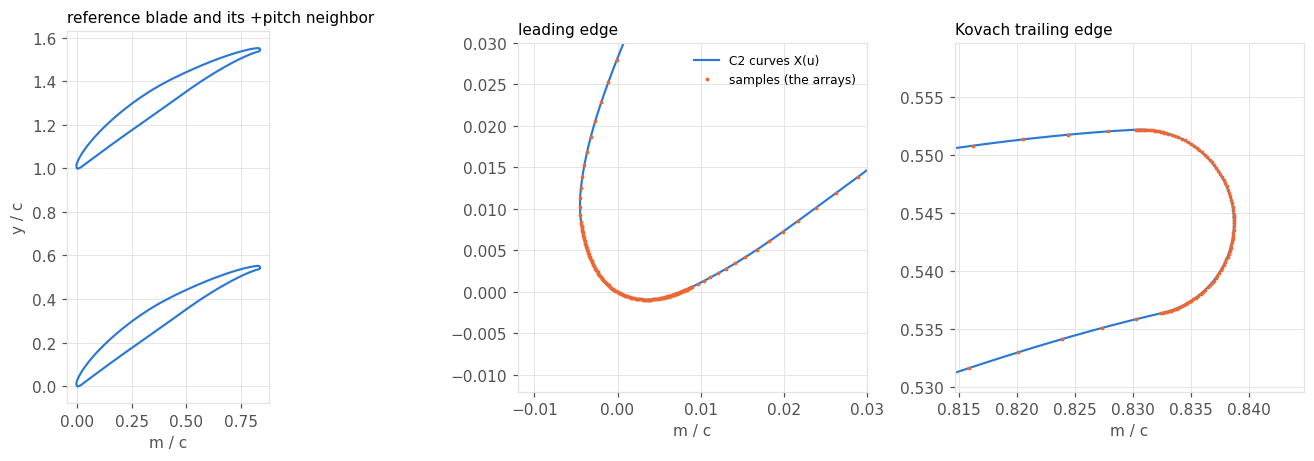

In [3]:
u_dense = np.linspace(0.0, 1.0, 20001)
dense = {name: getattr(curves, name).evaluate(u_dense) for name in ("suction", "pressure")}
fig, axes = plt.subplots(1, 3, figsize=(13, 4.3), gridspec_kw={"width_ratios": (1.5, 1, 1)})
for k, ax in enumerate(axes):
    for shift in (0.0, a.pitch):
        for name, X in dense.items():
            ax.plot(X[:, 0], X[:, 1] + shift, color=BLUE, linewidth=1.4,
                    label="C2 curves X(u)" if (shift == 0.0 and name == "suction") else None)
    if k:
        for surface, label in ((a.suction_surface, "samples (the arrays)"), (a.pressure_surface, None)):
            ax.plot(surface[:, 0], surface[:, 1], ".", color=ORANGE, markersize=3, label=label)
    ax.set_aspect("equal")
    ax.set_xlabel("m / c")
le, te = a.leading_edge_point, a.trailing_edge_point
axes[0].set(title="reference blade and its +pitch neighbor", ylabel="y / c")
axes[1].set(xlim=(le[0] - 0.012, le[0] + 0.03), ylim=(le[1] - 0.012, le[1] + 0.03), title="leading edge")
axes[2].set(xlim=(te[0] - 0.024, te[0] + 0.006), ylim=(te[1] - 0.015, te[1] + 0.015), title="Kovach trailing edge")
axes[1].legend(loc="upper right")
fig.tight_layout()

## 3. Coordinates and the grid (Aungier Secs. 5.2 and 5.3)

In the planar cascade $y = r\theta$ is the tangential distance, so Aungier's $r\,\partial\theta/\partial m$ is just
$\partial y/\partial m$. The two walls of the passage are $y_0(m)$ and $y_1(m)$ (Fig. 5-3), and

$$\xi = \int \frac{dm}{\cos\beta} \quad\text{(Eq. 5-1)}, \qquad
\eta = \frac{y - y_0(m)}{y_1(m) - y_0(m)} \quad\text{(Eq. 5-2)}, \qquad
S(m) = y_1(m) - y_0(m) \quad\text{(Eq. 5-9)}.$$

Solved for $y$, Eq. 5-2 maps the unit rectangle onto the passage:

$$y(m, \eta) = y_0(m) + \eta\,S(m),$$

and $\eta = 0$ and $\eta = 1$ give the walls exactly. Its Jacobian is
$\begin{bmatrix} 1 & 0 \\ \tan\beta & S \end{bmatrix}$, so $\det J = S$.

**The grid** (Sec. 5.3, Fig. 5-5):

- one constant $\Delta m$ from the far inlet to the far exit and one constant $\Delta\eta$ (p. 87);
- on the blade stations, $y_0$ is the passage-facing upper side of the reference blade and $y_1$ the passage-facing
  lower side of its +pitch neighbor;
- ahead of and behind the blade, $y_0$ and $y_1$ are periodic side lines one pitch apart. Their angle runs linearly
  in $m$ from the blade angle ($\kappa_{LE}$, $\kappa_{TE}$) to the far flow angle, because the far boundary
  condition (Eq. 5-33) wants the grid lines along the flow there (p. 86). The extensions are one true chord long
  by default;
- Aungier only asks that the first and last grid points on the blade lie inside the passage. Here the blade stations
  are exactly the stations whose line cuts the blade: the first one behind the nose tip, the last one ahead of the
  tail end, wherever they fall relative to the chord-line LE and TE points.

In [4]:
SETTINGS = GridSettings(n_passage=101, n_eta=31)     # one chord of extension on each side, the default
INLET_ANGLE = math.radians(45.0)                       # far-inlet flow angle; the exit starts at kappa_te
g = gr.make_grid(cascade, SETTINGS, INLET_ANGLE)
f, l = g.first_blade_i, g.last_blade_i
print(f"{len(g.m)} stations x {len(g.eta)} eta nodes, dm = {g.dm:.5f} c, deta = {g.deta:.4f}")
print(f"inlet stations 0..{f - 1}, blade stations {f}..{l} ({l - f + 1}), exit stations {l + 1}..{len(g.m) - 1}")
print(f"first blade station m = {g.m_first_blade:+.5f} c, {g.actual_le_offset:+.5f} c from the LE point "
      f"(negative: inside the nose, ahead of m_le)")
print(f"last blade station  m = {g.m_last_blade:+.5f} c, {g.actual_te_offset:+.5f} c from the TE point")
print("walls on the authoritative curves:", g.has_wall_curves,
      "| the cascade's own curve objects:", g.boundaries.blade_curves is curves)

343 stations x 31 eta nodes, dm = 0.00830 c, deta = 0.0333
inlet stations 0..119, blade stations 120..221 (102), exit stations 222..342
first blade station m = -0.00398 c, -0.00398 c from the LE point (negative: inside the nose, ahead of m_le)
last blade station  m = +0.83435 c, -0.00432 c from the TE point
walls on the authoritative curves: True | the cascade's own curve objects: True


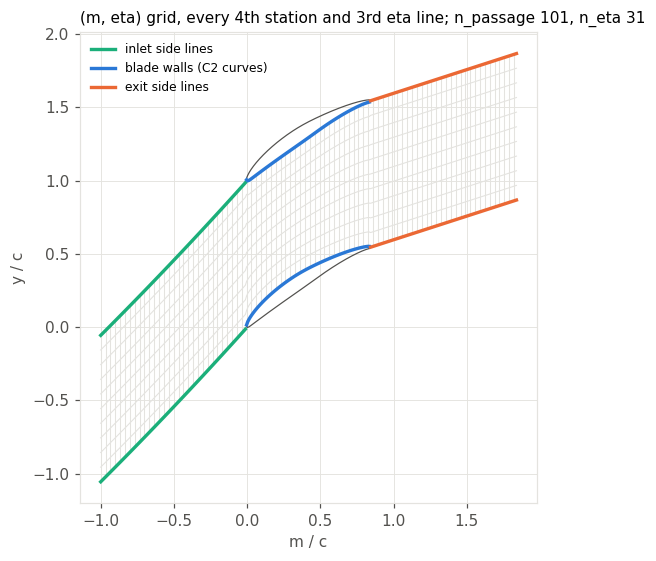

In [5]:
fig, ax = plt.subplots(figsize=(13, 5.2))
for j in range(0, len(g.eta), 3):
    ax.plot(g.nodes[:, j, 0], g.nodes[:, j, 1], color=RULE, linewidth=0.7, zorder=1)
for i in range(0, len(g.m), 4):
    ax.plot(g.nodes[i, :, 0], g.nodes[i, :, 1], color=RULE, linewidth=0.7, zorder=1)
for rows, color, label in ((slice(0, f), AQUA, "inlet side lines"), (slice(f, l + 1), BLUE, "blade walls (C2 curves)"),
                           (slice(l + 1, None), ORANGE, "exit side lines")):
    ax.plot(g.nodes[rows, 0, 0], g.nodes[rows, 0, 1], color=color, linewidth=2.2, label=label, zorder=3)
    ax.plot(g.nodes[rows, -1, 0], g.nodes[rows, -1, 1], color=color, linewidth=2.2, zorder=3)
for shift in (0.0, a.pitch):
    for X in dense.values():
        ax.plot(X[:, 0], X[:, 1] + shift, color=MUTED, linewidth=0.8, zorder=2)
ax.set(aspect="equal", xlabel="m / c", ylabel="y / c",
       title=f"(m, eta) grid, every 4th station and 3rd eta line; n_passage {SETTINGS.n_passage}, n_eta {SETTINGS.n_eta}")
ax.legend(loc="upper left")
fig.tight_layout()

## 4. The wall nodes are points of the C2 curve

For each blade station grid.py solves $m(u) = m_i$ on the curves themselves (`grid.py`, docstring section 7):

1. Each curve is cut, once, into **branches** on which $m(u)$ and $y(u)$ are both strictly monotone. The cuts are the
   exact roots of $m'(u)$ and $y'(u)$, polished on the curve's own derivative. On a branch the line $x = m_i$ has at
   most one root.
2. Every branch whose $m$ range holds $m_i$ gives one root, by bisection on $u$ to round-off.
3. **The passage-facing root is chosen by topology, not by a surface name:** the highest crossing is the lower wall
   (reference blade), the lowest crossing moved up one pitch is the upper wall (neighbor). Near a rounded nose or a
   Kovach tail one curve is cut twice, and then one wall lies on the "other" named surface. That is correct and
   recorded, not corrected.
4. The wall node is $\mathbf{X}(u_i)$, and `wall_identity` keeps the curve and $u$ of each node.

The cell below evaluates each node's curve directly at its stored $u$, independent of grid.py's own code path.

In [6]:
walls = slice(f, l + 1)
for side, column, shift in (("lower", 0, 0.0), ("upper", -1, a.pitch)):
    wall = getattr(g.wall_identity, side)
    X = np.array([getattr(curves, name).evaluate(u) for name, u in zip(wall.surface, wall.u)])
    names, counts = np.unique(wall.surface, return_counts=True)
    print(f"{side} wall: max |m(u_i) - m_i| = {np.abs(X[:, 0] - g.m[walls]).max():.1e} c, "
          f"max |y_grid - y(u_i)| = {np.abs(X[:, 1] + shift - g.nodes[walls, column, 1]).max():.1e} c, "
          f"nodes per curve {dict(zip(names.tolist(), counts.tolist()))}")

print(f"\n{'i':>4} {'m/c':>9} | {'lower: curve':>13} {'u':>10} {'y/c':>9} | {'upper: curve':>13} {'u':>10} {'y/c':>9}")
for i in (*range(f, f + 3), *range(l - 2, l + 1)):
    k = i - f
    lo, up = g.wall_identity.lower, g.wall_identity.upper
    print(f"{i:4d} {g.m[i]:+9.5f} | {lo.surface[k]:>13} {lo.u[k]:10.7f} {g.nodes[i, 0, 1]:+9.5f} | "
          f"{up.surface[k]:>13} {up.u[k]:10.7f} {g.nodes[i, -1, 1]:+9.5f}")

lower wall: max |m(u_i) - m_i| = 3.3e-16 c, max |y_grid - y(u_i)| = 0.0e+00 c, nodes per curve {'suction': 102}
upper wall: max |m(u_i) - m_i| = 3.3e-16 c, max |y_grid - y(u_i)| = 0.0e+00 c, nodes per curve {'pressure': 101, 'suction': 1}

   i       m/c |  lower: curve          u       y/c |  upper: curve          u       y/c
 120  -0.00398 |       suction  0.0159871  +0.01537 |       suction  0.0071897  +1.00619
 121  +0.00432 |       suction  0.0390980  +0.03817 |      pressure  0.0044637  +0.99910
 122  +0.01263 |       suction  0.0561843  +0.05411 |      pressure  0.0134481  +1.00253
 219  +0.81775 |       suction  0.9761474  +0.55099 |      pressure  0.9736406  +1.53226
 220  +0.82605 |       suction  0.9840815  +0.55188 |      pressure  0.9822557  +1.53476
 221  +0.83435 |       suction  0.9921140  +0.55129 |      pressure  0.9908288  +1.53706


The first blade station sits a few hundredths of $\Delta m$ behind the nose tip, ahead of the LE point. Its line meets
the suction curve twice, once on each side of the tip. The upper root faces the passage from the reference blade (the
lower wall), and the lower root, on the nose underside, faces it from the neighbor (the upper wall). So the upper wall
starts on the neighbor's suction surface and moves onto its pressure surface as soon as the LE point is passed.

nose tip at u = 0.01135; roots of m(u) = m_f on the suction curve: u = 0.007189707, 0.015987130
grid: lower wall u = 0.015987130 (suction), upper wall u = 0.007189707 (suction, on the neighbor)


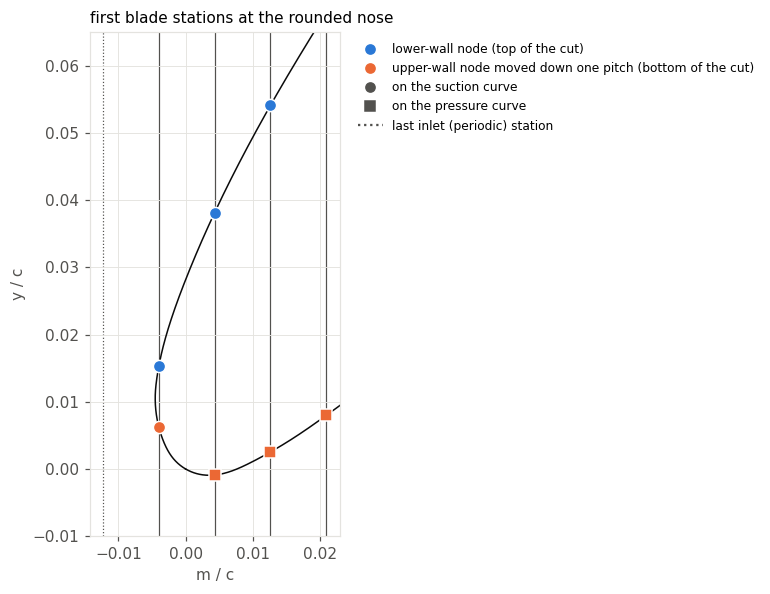

In [7]:
suction = curves.suction
m_s = dense["suction"][:, 0]
u_tip = u_dense[np.argmin(m_s)]
roots = []
for lo_u, hi_u in ((0.0, u_tip), (u_tip, 1.0)):            # one root on each side of the tip (independent check)
    roots.append(brentq(lambda s: float(suction.evaluate(s)[0]) - g.m[f], lo_u, hi_u, xtol=1e-16))
print(f"nose tip at u = {u_tip:.5f}; roots of m(u) = m_f on the suction curve: u = {roots[0]:.9f}, {roots[1]:.9f}")
print(f"grid: lower wall u = {g.wall_identity.lower.u[0]:.9f} ({g.wall_identity.lower.surface[0]}), "
      f"upper wall u = {g.wall_identity.upper.u[0]:.9f} ({g.wall_identity.upper.surface[0]}, on the neighbor)")

fig, ax = plt.subplots(figsize=(7.5, 5.5))
for X in dense.values():
    ax.plot(X[:, 0], X[:, 1], color=INK, linewidth=1.0)
for i in range(f - 1, f + 4):
    ax.axvline(g.m[i], color=MUTED, linewidth=0.8, linestyle=":" if i == f - 1 else "-", zorder=0)
markers = {"suction": "o", "pressure": "s"}
for i in range(f, f + 4):
    k = i - f
    for side, column, shift, color in (("lower", 0, 0.0, BLUE), ("upper", -1, a.pitch, ORANGE)):
        ax.plot(g.m[i], g.nodes[i, column, 1] - shift, markers[getattr(g.wall_identity, side).surface[k]],
                color=color, markersize=8, markeredgecolor="white")
ax.plot([], [], "o", color=BLUE, label="lower-wall node (top of the cut)")
ax.plot([], [], "o", color=ORANGE, label="upper-wall node moved down one pitch (bottom of the cut)")
ax.plot([], [], "o", color=MUTED, label="on the suction curve")
ax.plot([], [], "s", color=MUTED, label="on the pressure curve")
ax.plot([], [], ":", color=MUTED, label="last inlet (periodic) station")
ax.set(xlim=(g.m[f - 1] - 0.002, g.m[f + 3] + 0.002), ylim=(-0.01, 0.065), aspect="equal", xlabel="m / c", ylabel="y / c",
       title="first blade stations at the rounded nose")
ax.legend(loc="upper left", bbox_to_anchor=(1.03, 1.0))
fig.tight_layout()

## 5. Metrics: exact wall angles from the same curve (Eqs. 5-3, 5-9)

On a C2 blade wall the slope is the curve's own derivative at the node's $u$, with $m$ as the local coordinate:

$$\tan\beta_{wall} = \frac{dy}{dm} = \frac{y_u}{m_u}, \qquad
\frac{d\tan\beta_{wall}}{dm} = \frac{d^2y}{dm^2} = \frac{y_{uu}\,m_u - y_u\,m_{uu}}{m_u^3}.$$

No neighbouring node enters, so the first and last blade stations carry the true slope. On the side lines `metrics.py`
keeps its second-order differences, inside each region, so no stencil crosses the LE or TE transition. Inside the
passage nothing is evaluated on a curve: the map $y = y_0 + \eta S$ gives exactly

$$\tan\beta = (1-\eta)\tan\beta_0 + \eta\tan\beta_1 \ \text{(Eq. 5-3)},\qquad
\frac{\partial\tan\beta}{\partial m} = (1-\eta)\frac{d\tan\beta_0}{dm} + \eta\frac{d\tan\beta_1}{dm},\qquad
\frac{\partial\tan\beta}{\partial\eta} = \tan\beta_1 - \tan\beta_0 = \frac{dS}{dm}.$$

$\beta$, $\sin\beta$ and $\cos\beta$ follow from $\tan\beta$ by $\cos\beta = 1/\sqrt{1+\tan^2\beta}$,
$\sin\beta = \tan\beta\cos\beta$, $\beta = \arctan(\tan\beta)$. Where $m_u \to 0$ (a vertical tangent at a nose tip or
tail end) the curve stays smooth but $y(m)$ does not. Grid stations never sit there, and a node numerically at it
would be refused, not clipped.

exact wall slopes from the C2 curves: True
first blade station: beta lower +79.25 deg, upper -75.49 deg
last blade station:  beta lower -27.24 deg, upper +27.21 deg
min S = 0.877949 c (not the throat 0.721518 c: S runs along y, the throat across the passage)
min cos(beta) = 0.1866, max |d tan(beta)/dm| = 3.693e+03 1/c


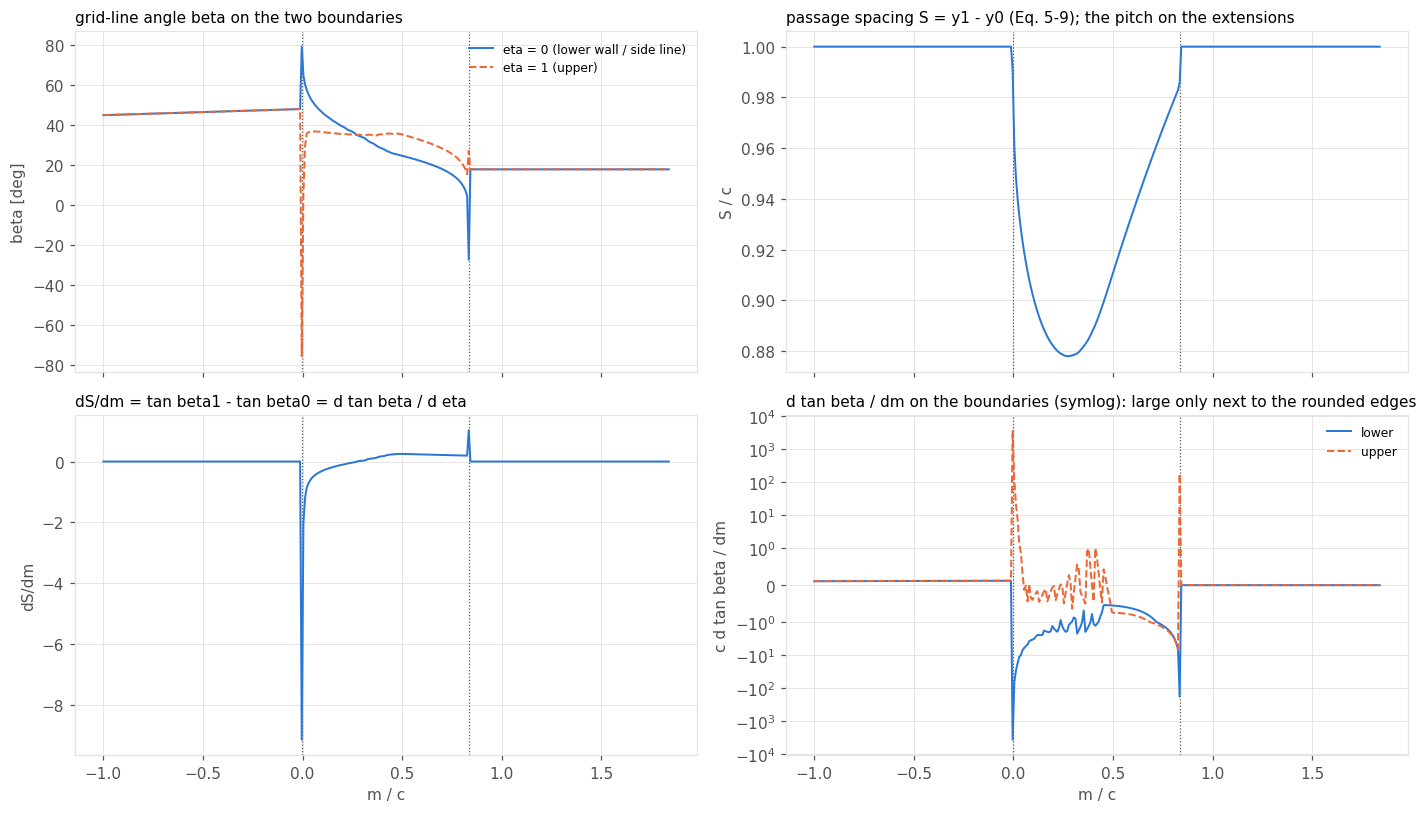

In [8]:
gm = mt.build_metrics(g)
print("exact wall slopes from the C2 curves:", gm.exact_wall_slopes)
print(f"first blade station: beta lower {math.degrees(gm.beta[f, 0]):+.2f} deg, upper {math.degrees(gm.beta[f, -1]):+.2f} deg")
print(f"last blade station:  beta lower {math.degrees(gm.beta[l, 0]):+.2f} deg, upper {math.degrees(gm.beta[l, -1]):+.2f} deg")
print(f"min S = {gm.S.min():.6f} c (not the throat {a.throat_opening:.6f} c: S runs along y, the throat across the passage)")
print(f"min cos(beta) = {gm.cos_beta.min():.4f}, max |d tan(beta)/dm| = {np.abs(gm.dtan_beta_dm).max():.3e} 1/c")

fig, axes = plt.subplots(2, 2, figsize=(13, 7.5), sharex=True)
for ax in axes.flat:
    ax.axvline(g.m_first_blade, color=MUTED, linewidth=0.8, linestyle=":")
    ax.axvline(g.m_last_blade, color=MUTED, linewidth=0.8, linestyle=":")
axes[0, 0].plot(g.m, np.degrees(gm.beta[:, 0]), color=BLUE, linewidth=1.3, label="eta = 0 (lower wall / side line)")
axes[0, 0].plot(g.m, np.degrees(gm.beta[:, -1]), color=ORANGE, linewidth=1.3, linestyle="--", label="eta = 1 (upper)")
axes[0, 0].set(title="grid-line angle beta on the two boundaries", ylabel="beta [deg]")
axes[0, 0].legend()
axes[0, 1].plot(g.m, gm.S, color=BLUE, linewidth=1.3)
axes[0, 1].set(title="passage spacing S = y1 - y0 (Eq. 5-9); the pitch on the extensions", ylabel="S / c")
axes[1, 0].plot(g.m, gm.dS_dm, color=BLUE, linewidth=1.3)
axes[1, 0].set(title="dS/dm = tan beta1 - tan beta0 = d tan beta / d eta", ylabel="dS/dm", xlabel="m / c")
axes[1, 1].plot(g.m, gm.dtan_beta0_dm, color=BLUE, linewidth=1.3, label="lower")
axes[1, 1].plot(g.m, gm.dtan_beta1_dm, color=ORANGE, linewidth=1.3, linestyle="--", label="upper")
axes[1, 1].set_yscale("symlog", linthresh=1.0)
axes[1, 1].set(title="d tan beta / dm on the boundaries (symlog): large only next to the rounded edges",
               ylabel="c d tan beta / dm", xlabel="m / c")
axes[1, 1].legend()
fig.tight_layout()

The small ripples of $d\tan\beta/dm$ between $m/c \approx 0.1$ and $0.5$ are geometry, not noise: on a wall
$d^2y/dm^2 = \kappa/\cos^3\beta$, and the C2 surface changes its curvature over short, monotone transitions at the
stations of the thickness table (`geometry.py`, "Surface continuity"). The large values sit only at the first and
last blade stations, next to the vertical tangents of the rounded nose and tail.

**Checks, each against something `metrics.py` does not use.** The identities hold to round-off by construction. The
last check takes no derivative formula at all: it differences $y(m)$ on the curve itself, each $y(m)$ a `brentq` root,
with Richardson extrapolation.

In [9]:
eta = g.eta
print("dS_dm == tan_beta1 - tan_beta0:              ", np.array_equal(gm.dS_dm, gm.tan_beta1 - gm.tan_beta0))
print("dtan_beta_deta is the dS_dm array:           ", gm.dtan_beta_deta is gm.dS_dm)
print("tan_beta affine in eta (Eq. 5-3):            ",
      np.array_equal(gm.tan_beta, (1 - eta) * gm.tan_beta0[:, None] + eta * gm.tan_beta1[:, None]))
print("dtan_beta_dm affine in eta:                  ",
      np.array_equal(gm.dtan_beta_dm, (1 - eta) * gm.dtan_beta0_dm[:, None] + eta * gm.dtan_beta1_dm[:, None]))
print("cos = 1/hypot(1, tan), sin = tan cos:        ",
      np.array_equal(gm.cos_beta, 1 / np.hypot(1, gm.tan_beta)) and np.array_equal(gm.sin_beta, gm.tan_beta * gm.cos_beta))


def y_on_curve(curve, u0, m, reach=2e-3):
    root = brentq(lambda s: float(curve.evaluate(s)[0]) - m, max(0.0, u0 - reach), min(1.0, u0 + reach), xtol=1e-16)
    return float(curve.evaluate(root)[1])


print(f"\n{'i':>4} {'m/c':>8} {'wall':6} {'tan exact':>11} {'tan Richardson':>15} {'dtan/dm exact':>14} {'Richardson':>12}")
h = 1e-4
for i in (f + 10, f + 30, f + 50, f + 70, f + 90):
    k = i - f
    for side, slope, dslope in (("lower", gm.tan_beta0, gm.dtan_beta0_dm), ("upper", gm.tan_beta1, gm.dtan_beta1_dm)):
        wall = getattr(g.wall_identity, side)
        curve, u0, m = getattr(curves, wall.surface[k]), wall.u[k], g.m[i]
        y = lambda x: y_on_curve(curve, u0, x)                                          # noqa: E731
        d1 = [(y(m + s) - y(m - s)) / (2 * s) for s in (h, h / 2)]
        d2 = [(y(m + s) - 2 * y(m) + y(m - s)) / s ** 2 for s in (h, h / 2)]
        print(f"{i:4d} {m:8.4f} {side:6} {slope[i]:+11.7f} {(4 * d1[1] - d1[0]) / 3:+15.7f} "
              f"{dslope[i]:+14.6f} {(4 * d2[1] - d2[0]) / 3:+12.6f}")

dS_dm == tan_beta1 - tan_beta0:               True
dtan_beta_deta is the dS_dm array:            True
tan_beta affine in eta (Eq. 5-3):             True
dtan_beta_dm affine in eta:                   True
cos = 1/hypot(1, tan), sin = tan cos:         True

   i      m/c wall     tan exact  tan Richardson  dtan/dm exact   Richardson
 130   0.0790 lower   +1.1185985      +1.1185985      -3.809918    -3.809918
 130   0.0790 upper   +0.7461404      +0.7461404      +0.032283    +0.032283
 150   0.2450 lower   +0.7532442      +0.7532442      -1.343548    -1.343548
 150   0.2450 upper   +0.7097805      +0.7097805      -0.009413    -0.009413
 170   0.4110 lower   +0.5259109      +0.5259109      -1.306438    -1.306439
 170   0.4110 upper   +0.7085732      +0.7085732      +1.008151    +1.008151
 190   0.5770 lower   +0.4155290      +0.4155290      -0.610496    -0.610496
 190   0.5770 upper   +0.6509576      +0.6509576      -0.785567    -0.785567
 210   0.7430 lower   +0.2821180      +0.2821180   

## 6. The hand-off itself: sampled walls against the curve

Before the hand-off a C2 grid read the sampled arrays through a PCHIP, and `metrics.py` differenced its nodes. That
reading is still reachable: the same cascade without its curves takes the old path. This is a check of the hand-off on
**one** geometry; it is **not** the C1-against-C2 comparison, which is planned for later.

In [10]:
sampled = gr.make_grid(replace(cascade, active_curves=None, normalized_curves=None), SETTINGS, INLET_ANGLE)
old = mt.build_metrics(sampled)
assert (sampled.first_blade_i, sampled.last_blade_i) == (f, l)
move = g.nodes[walls][:, [0, -1], 1] - sampled.nodes[walls][:, [0, -1], 1]
print(f"same stations and blade run; wall nodes moved by at most {np.abs(move).max():.1e} c "
      f"(RMS {np.sqrt(np.mean(move ** 2)):.1e} c): the PCHIP's own error between samples")
away = (g.m[walls] - g.m_first_blade >= 0.05) & (g.m_last_blade - g.m[walls] >= 0.05)
for side, new_t, old_t in (("lower", gm.tan_beta0, old.tan_beta0), ("upper", gm.tan_beta1, old.tan_beta1)):
    d_beta = np.degrees(np.arctan(new_t[walls]) - np.arctan(old_t[walls]))
    print(f"{side} wall: |beta_exact - beta_sampled| first 5 nodes "
          f"{' '.join(f'{x:5.2f}' for x in np.abs(d_beta[:5]))} deg, last 5 "
          f"{' '.join(f'{x:5.2f}' for x in np.abs(d_beta[-5:]))} deg, >= 0.05 c from the ends at most "
          f"{np.abs(d_beta[away]).max():.3f} deg")

same stations and blade run; wall nodes moved by at most 9.2e-06 c (RMS 1.5e-06 c): the PCHIP's own error between samples
lower wall: |beta_exact - beta_sampled| first 5 nodes  6.81  1.95  0.43  0.15  0.10 deg, last 5  0.04  0.06  0.12  3.74 18.11 deg, >= 0.05 c from the ends at most 0.095 deg
upper wall: |beta_exact - beta_sampled| first 5 nodes 19.39 18.07  1.48  1.05  0.00 deg, last 5  0.03  0.06  0.11  0.64 12.38 deg, >= 0.05 c from the ends at most 0.122 deg


## 7. Where the metrics go next: Eqs. 5-20 to 5-26 (not implemented yet)

With $\psi$ the stream function and $\mu = \dot m/(b\rho)$, the velocities are (Eqs. 5-18, 5-19)

$$W_m = \frac{\mu}{S}\frac{\partial\psi}{\partial\eta}, \qquad
W_\theta = \mu\left[\frac{\tan\beta}{S}\frac{\partial\psi}{\partial\eta} - \frac{\partial\psi}{\partial m}\right],$$

and the stream-function equation in divergence form is Eq. 5-20,

$$\frac{\partial F}{\partial\eta} - \frac{\partial G}{\partial m} = 0,\qquad
F = \mu\frac{1+\tan^2\beta}{S}\psi_\eta - \mu\tan\beta\,\psi_m,\qquad
G = \mu\tan\beta\,\psi_\eta - \mu S\,\psi_m,$$

expanded into Eq. 5-21,

$$A\,\psi_{\eta\eta} - 2B\,\psi_{\eta m} + C\,\psi_{mm} + D\,\psi_\eta + E\,\psi_m = 0,$$

$$A = \frac{\mu}{S\cos^2\beta},\quad B = \mu\tan\beta,\quad C = \mu S\quad\text{(Eqs. 5-22 to 5-24)},\qquad
D = \frac{\partial A}{\partial\eta} - \frac{\partial B}{\partial m},\quad
E = \frac{\partial C}{\partial m} - \frac{\partial B}{\partial\eta}\quad\text{(Eqs. 5-25, 5-26)}.$$

So the geometry has to supply $S$, $\tan\beta$ (with $\cos\beta$), $\partial\tan\beta/\partial m$,
$\partial\tan\beta/\partial\eta$ and $dS/dm$, which is exactly `GridMetrics`. $d^2S/dm^2$ never appears, so it is not
stored. The density enters through $\mu$ and is the job of `coefficients.py`.

For a constant $\mu$ the geometric parts are $D/\mu = 2\tan\beta\,(dS/dm)/S - \partial\tan\beta/\partial m$ and
$E/\mu = dS/dm - \partial\tan\beta/\partial\eta$, which is **zero** by the identity above. The cell evaluates both on
the blade stations, as an illustration only, not as the solver's coefficients.

In [11]:
T, S = gm.tan_beta[walls], gm.S[walls, None]
D_geo = 2 * T * gm.dS_dm[walls, None] / S - gm.dtan_beta_dm[walls]
E_geo = gm.dS_dm[walls] - gm.dtan_beta_deta[walls]
print(f"E / mu on the blade stations: max |E| = {np.abs(E_geo).max():.1e} (exactly zero)")
print(f"D / mu on the blade stations: median |D| = {np.median(np.abs(D_geo)):.3g} 1/c, "
      f"largest {np.abs(D_geo).max():.3g} 1/c at station {f + int(np.argmax(np.abs(D_geo).max(axis=1)))} "
      f"(the first blade station is {f}: the nose)")

E / mu on the blade stations: max |E| = 0.0e+00 (exactly zero)
D / mu on the blade stations: median |D| = 1.02 1/c, largest 3.62e+03 1/c at station 120 (the first blade station is 120: the nose)


## 8. Robustness: resolution, eta, chord, exit angle

Diagnostics only; no limit is imposed. The first and last blade stations move with the grid phase, so the largest
slopes do too: they are set by how close a station falls to the nose tip or tail end.

In [12]:
print(f"{'n_passage':>9} {'first':>6} {'last':>6} {'tip gap/dm':>10} {'min S/c':>11} {'max|tan b|':>10} "
      f"{'min cos b':>9} {'max|dtan/dm| c':>14}")
m_tip = min(dense["suction"][:, 0].min(), dense["pressure"][:, 0].min())
for n in (31, 51, 81, 101, 141, 201, 401):
    gn = gr.make_grid(cascade, GridSettings(n_passage=n, n_eta=11), INLET_ANGLE)
    mn = mt.build_metrics(gn)
    print(f"{n:9d} {gn.first_blade_i:6d} {gn.last_blade_i:6d} {(gn.m_first_blade - m_tip) / gn.dm:10.3f} "
          f"{mn.S.min():11.8f} {np.abs(mn.tan_beta).max():10.3f} {mn.cos_beta.min():9.4f} "
          f"{np.abs(mn.dtan_beta_dm).max():14.4e}")

reference = mt.build_metrics(gr.make_grid(cascade, GridSettings(n_passage=101, n_eta=11), INLET_ANGLE))
same = all(np.array_equal(getattr(mt.build_metrics(gr.make_grid(cascade, GridSettings(n_passage=101, n_eta=n_eta),
                                                                  INLET_ANGLE)), name), getattr(reference, name))
           for n_eta in (31, 61, 101) for name in ("S", "tan_beta0", "tan_beta1", "dtan_beta0_dm", "dtan_beta1_dm"))
print("\nn_eta 11 / 31 / 61 / 101: wall and station metrics identical:", same)

metre = make_cascade(replace(SPEC, physical_chord=0.05))
gm_metre = mt.build_metrics(gr.make_grid(metre, SETTINGS, INLET_ANGLE))
print("chord 0.05 m: S/c and beta as for chord 1:",
      np.allclose(gm_metre.S / 0.05, gm.S, rtol=1e-13), np.allclose(gm_metre.beta, gm.beta, rtol=0, atol=1e-12),
      "| d tan(beta)/dm scales with 1/c:",
      np.allclose(gm_metre.dtan_beta_dm * 0.05, gm.dtan_beta_dm, rtol=0, atol=2e-11 * np.abs(gm.dtan_beta_dm).max()))

turned = gr.rebuild_exit(g, cascade.kappa_te + math.radians(5.0))
print("rebuild_exit to kappa_te + 5 deg: inlet and blade nodes and wall u unchanged:",
      np.array_equal(turned.nodes[:l + 1], g.nodes[:l + 1])
      and np.array_equal(turned.wall_identity.lower.u, g.wall_identity.lower.u)
      and np.array_equal(turned.wall_identity.upper.u, g.wall_identity.upper.u))

n_passage  first   last tip gap/dm     min S/c max|tan b| min cos b max|dtan/dm| c
       31     37     68      0.178  0.87794537      3.505    0.2744     6.0533e+03


       51     61    112      0.332  0.87796979      2.429    0.3807     1.2160e+03
       81     97    177      0.913  0.87793987      2.091    0.4314     1.5976e+02


      101    120    221      0.066  0.87794904      5.266    0.1866     3.6931e+03
      141    168    308      0.724  0.87793933      2.563    0.3634     2.4101e+02


      201    239    440      0.535  0.87793935      3.108    0.3063     7.3062e+02
      401    476    878      0.122  0.87793952      6.968    0.1421     1.1491e+04



n_eta 11 / 31 / 61 / 101: wall and station metrics identical: True


chord 0.05 m: S/c and beta as for chord 1: True True | d tan(beta)/dm scales with 1/c: True
rebuild_exit to kappa_te + 5 deg: inlet and blade nodes and wall u unchanged: True


## 9. Summary

- The solver geometry is **C2**. `grid.py` puts every blade-wall node on the authoritative curve, $\mathbf{X}(u_i)$
  with $m(u_i) = m_i$ to round-off, and keeps the curve and $u$ of each node. `metrics.py` takes the wall angles and
  their $m$ derivatives from the same curve at the same $u$. No second wall representation sits in between.
- The theory followed is Aungier's Chapter 5: the planar stream sheet, the walls of Fig. 5-3, the coordinates of
  Eqs. 5-1 and 5-2, the grid-line slope of Eq. 5-3, the spacing of Eq. 5-9 and the grid rules of Sec. 5.3 and Fig. 5-5.
  `GridMetrics` holds what Eqs. 5-20 to 5-26 need from the geometry.
- Unchanged: the stations, the extensions and `rebuild_exit`, the linear eta map, and the C1 path.
- **A fair C1-against-C2 scientific comparison is planned for later**, after an exact piecewise-C1 derivative path.
- Next: `coefficients.py` (A to E with the density), then the finite differences and the solver loops.